# Pharmakon — engine walkthrough

Run top to bottom. Every number here comes from `app/`, not from this notebook —
if a cell disagrees with the test suite, the test suite is right.

**Setup in VS Code:** open the repo folder, install the Python + Jupyter
extensions, then select the interpreter where `requirements.txt` is installed
(`Ctrl/Cmd+Shift+P` → *Python: Select Interpreter*). The first cell adds the
repo root to `sys.path` so `import app` resolves without installing anything.

Not a medical device. One-compartment model, population-average parameters,
educational use only.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "app").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt

from app.pk.engine import Dose, PKParams, bateman, superpose, time_grid, tmax_hours, troughs_per_day
from app.pk.individualize import Patient, adjusted_ke, cockcroft_gault
from app.registry.loader import load_registry
from app.detect.alerts import LoggedDose, detect_accumulation, detect_duplication

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})
registry = load_registry()
print(f"registry: {len(registry.all())} substances, {len(registry.unverified())} unverified")

registry: 21 substances, 21 unverified


## 1. The ninety-second demo — a 4pm coffee at midnight

Start here with anyone you're explaining this to. Everyone has lived it, and it
makes half-life visible in about ten seconds.

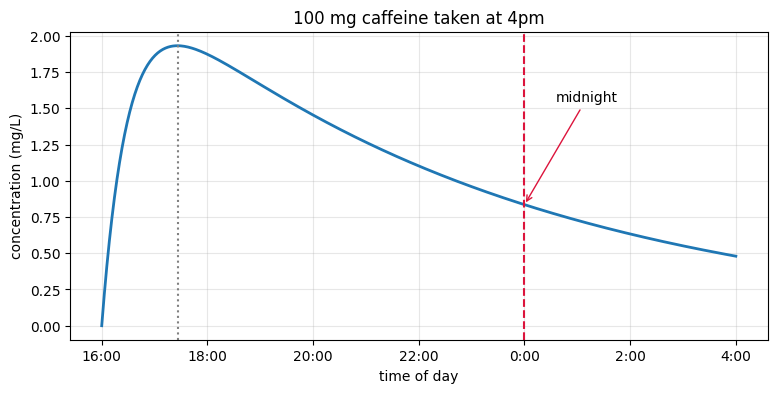

peak      1.932 mg/L at 1.4 h
midnight  0.835 mg/L = 43% of peak


In [2]:
caffeine = registry.pk_params("caffeine")
me = Patient(age_years=22, weight_kg=70, sex="male")

t = np.linspace(0, 12, 500)
conc = bateman(t, 100.0, caffeine, me.weight_kg)

fig, ax = plt.subplots()
ax.plot(t, conc, lw=2)
ax.axvline(tmax_hours(caffeine), ls=":", c="gray")
ax.axvline(8, ls="--", c="crimson")
ax.set_xticks(range(0, 13, 2))
ax.set_xticklabels([f"{(16 + h) % 24}:00" for h in range(0, 13, 2)])
ax.set_xlabel("time of day"); ax.set_ylabel("concentration (mg/L)")
ax.set_title("100 mg caffeine taken at 4pm")
ax.annotate("midnight", xy=(8, conc[np.searchsorted(t, 8)]),
            xytext=(8.6, conc.max() * 0.8), arrowprops=dict(arrowstyle="->", color="crimson"))
plt.show()

peak = conc.max()
print(f"peak      {peak:.3f} mg/L at {t[conc.argmax()]:.1f} h")
print(f"midnight  {conc[np.searchsorted(t, 8)]:.3f} mg/L "
      f"= {100 * conc[np.searchsorted(t, 8)] / peak:.0f}% of peak")

## 2. Verifying the elimination path

The spec's first concrete test: caffeine, half-life ~5 h, concentration should
halve every 5 hours once absorption is done. If this doesn't hold, nothing
downstream is trustworthy.

In [3]:
peak_t = tmax_hours(caffeine)
samples = np.array([peak_t + 20, peak_t + 25, peak_t + 30])
c = bateman(samples, 100.0, caffeine, 70.0)
for i in range(1, len(c)):
    print(f"+5 h ratio: {c[i] / c[i-1]:.4f}   (expect 0.5000)")

+5 h ratio: 0.5000   (expect 0.5000)
+5 h ratio: 0.5000   (expect 0.5000)


## 3. Superposition — where accumulation comes from

One dose decays. Repeated doses stack, and whether the floor climbs depends
entirely on the half-life relative to the dosing interval. Same code, two
substances, opposite outcomes.

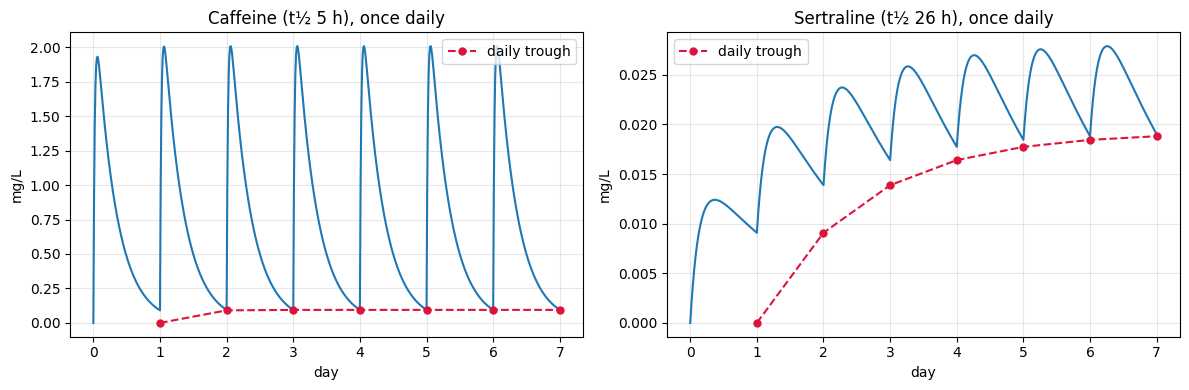

Caffeine troughs : [0.0, 0.091, 0.094, 0.094, 0.094, 0.094, 0.094]
Sertraline troughs: [0.0, 0.009, 0.014, 0.016, 0.018, 0.018, 0.019]


In [4]:
sertraline = registry.pk_params("sertraline")
grid = time_grid(0.0, 24 * 7)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (params, label, dose_mg) in zip(
    axes,
    [(caffeine, "Caffeine (t½ 5 h)", 100.0), (sertraline, "Sertraline (t½ 26 h)", 50.0)],
):
    doses = [Dose(24.0 * d, dose_mg) for d in range(7)]
    conc = superpose(doses, params, me.weight_kg, grid)
    troughs = troughs_per_day(grid, conc)
    ax.plot(grid / 24, conc, lw=1.5)
    ax.plot(np.arange(len(troughs)) + 1, troughs, "o--", c="crimson", ms=5, label="daily trough")
    ax.set_xlabel("day"); ax.set_ylabel("mg/L"); ax.set_title(f"{label}, once daily")
    ax.legend()
plt.tight_layout(); plt.show()

print("Caffeine troughs :", [round(v, 3) for v in troughs_per_day(grid, superpose([Dose(24.0*d, 100.0) for d in range(7)], caffeine, 70, grid))])
print("Sertraline troughs:", [round(v, 3) for v in troughs_per_day(grid, superpose([Dose(24.0*d, 50.0) for d in range(7)], sertraline, 70, grid))])

The caffeine floor is flat — steady state on day one. The sertraline floor
climbs for a week. A snapshot interaction checker sees nothing wrong in either
case, which is the whole argument for this project.

## 4. Individualization

Cockcroft–Gault, and the deliberate asymmetry: renal impairment scales `ke`
numerically, hepatic impairment does not. There is no validated one-line
hepatic correction, and inventing one would make the model look more precise
than it is. It surfaces as a note instead.

In [5]:
people = {
    "healthy 30 y, no lab value": Patient(30, 70, "male"),
    "healthy 30 y, Scr 1.0":      Patient(30, 70, "male", 1.0),
    "78 y female, Scr 1.6":       Patient(78, 62, "female", 1.6),
}
metformin = registry.pk_params("metformin")

for label, p in people.items():
    crcl = cockcroft_gault(p)
    ke, notes = adjusted_ke(metformin, p)
    print(f"{label}")
    print(f"   CrCl {('%.0f mL/min' % crcl) if crcl else 'unknown'}   "
          f"ke {ke:.4f}/h   half-life {np.log(2)/ke:.1f} h")
    for n in notes:
        print(f"   note: {n}")
    print()

healthy 30 y, no lab value
   CrCl unknown   ke 0.1155/h   half-life 6.0 h
   note: Renally cleared. No serum creatinine on file, so population clearance was used. Entering a recent creatinine value will sharpen this curve.

healthy 30 y, Scr 1.0
   CrCl 107 mL/min   ke 0.1235/h   half-life 5.6 h
   note: Renal adjustment applied: estimated CrCl 107 mL/min vs reference 100; elimination scaled by 1.07.

78 y female, Scr 1.6
   CrCl 28 mL/min   ke 0.0328/h   half-life 21.2 h
   note: Renal adjustment applied: estimated CrCl 28 mL/min vs reference 100; elimination scaled by 0.28.



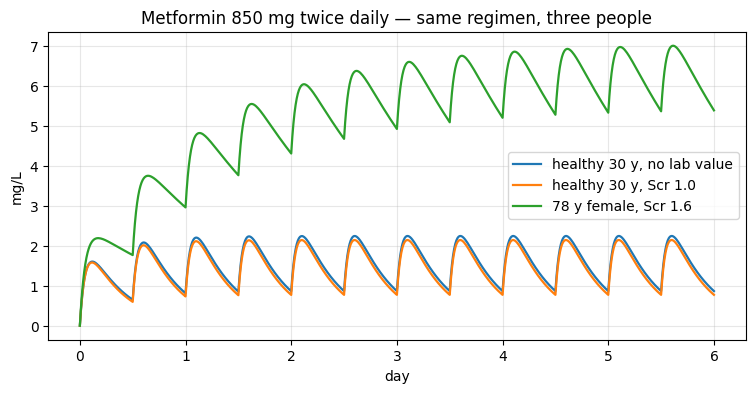

In [6]:
grid = time_grid(0.0, 24 * 6)
doses = [Dose(12.0 * i, 850.0) for i in range(12)]

fig, ax = plt.subplots()
for label, p in people.items():
    ke, _ = adjusted_ke(metformin, p)
    ax.plot(grid / 24, superpose(doses, metformin, p.weight_kg, grid, ke=ke), lw=1.6, label=label)
ax.set_xlabel("day"); ax.set_ylabel("mg/L")
ax.set_title("Metformin 850 mg twice daily — same regimen, three people")
ax.legend(); plt.show()

This plot is the argument for why one-size-fits-all warnings fail. Identical
regimen, materially different exposure.

## 5. Duplicate detection — the canonical acetaminophen case

A cold medicine and a headache tablet. Neither product looks dangerous.

In [7]:
apap = registry.pk_params("acetaminophen")
entry = registry.get("acetaminophen")

day = [
    LoggedDose("d1", "acetaminophen",  0.0,  650.0, "NyQuil"),
    LoggedDose("d2", "acetaminophen",  5.0, 1000.0, "Extra Strength Tylenol"),
    LoggedDose("d3", "acetaminophen", 11.0, 1000.0, "Extra Strength Tylenol"),
    LoggedDose("d4", "acetaminophen", 17.0,  650.0, "NyQuil"),
]

alert = detect_duplication(day, apap, entry["name"], entry["threshold_24h_mg"], 20.0, me)
print(f"[{alert.severity}] {alert.kind}\n{alert.message}\n")
print("traceable to:", alert.contributing_dose_ids)
print("payload:", alert.payload)

[caution] duplication
Acetaminophen is in 2 of the products you logged (Extra Strength Tylenol, NyQuil). Your 24-hour total is 3300 mg, which is approaching the 4000 mg limit. Talk to a pharmacist or your prescriber.

traceable to: ['d1', 'd2', 'd3', 'd4']
payload: {'total_mg': 3300.0, 'threshold_mg': 4000, 'base_threshold_mg': 4000, 'products': ['Extra Strength Tylenol', 'NyQuil']}


Note `contributing_dose_ids`. Every alert carries them — the `Alert` dataclass
makes it impossible to construct one without. An alert the user can't trace
back to specific doses isn't actionable.

Now the same day for someone with recorded liver impairment. The threshold
drops; the message explains why rather than silently changing a number.

In [8]:
impaired = Patient(30, 70, "male", hepatic_impairment="moderate")
a2 = detect_duplication(day, apap, entry["name"], entry["threshold_24h_mg"], 20.0, impaired)
print(f"[{a2.severity}] {a2.message}")
for n in a2.notes:
    print("note:", n)

[urgent] Acetaminophen is in 2 of the products you logged (Extra Strength Tylenol, NyQuil). Your 24-hour total is 3300 mg, which exceeds the 2000 mg limit. Talk to a pharmacist or your prescriber.
note: Threshold reduced from 4000 to 2000 mg because of recorded moderate hepatic impairment.


## 6. Accumulation detection

Fit a line to the daily troughs. Fires on sertraline, stays quiet on caffeine —
staying quiet is the harder and more important half.

In [9]:
for sid, label, dose_mg in [("sertraline", "Sertraline", 50.0), ("caffeine", "Caffeine", 100.0)]:
    logs = [LoggedDose(f"{sid}{i}", sid, 24.0 * i, dose_mg, label) for i in range(6)]
    a = detect_accumulation(logs, registry.pk_params(sid), label, me, 120.0)
    print(f"{label:12} -> {a.message if a else 'no alert (floor is flat)'}\n")

Sertraline   -> Sertraline is accumulating. Your daily low point has risen from 0.009 to 0.018 mg/L across 4 days, meaning each dose is landing before the previous one has cleared. This is an estimate from a population-average model — worth raising with your prescriber, not a reason to change your dose on your own.

Caffeine     -> no alert (floor is flat)



## 7. What the engine refuses to model

Alcohol follows zero-order kinetics — a fixed amount per hour, not a fixed
fraction. The one-compartment first-order model does not apply. It refuses
rather than drawing a confident wrong curve.

In [10]:
from app.pk.engine import UnsupportedKinetics

ethanol = PKParams("ethanol", 1.0, 0.6, 1.0, 3.0, "hepatic", kinetics="zero_order")
try:
    ethanol.check_modelable()
except UnsupportedKinetics as e:
    print("refused:", e)

logs = [LoggedDose(f"e{i}", "ethanol", 24.0 * i, 14.0, "Beer") for i in range(6)]
a = detect_accumulation(logs, ethanol, "Alcohol", me, 120.0)
print(f"\nalert kind: {a.kind}  severity: {a.severity}")

refused: ethanol follows zero_order kinetics; the one-compartment first-order model does not apply. Surface this to the user rather than returning a wrong curve.

alert kind: unmodelable  severity: info


## 8. Registry status

Every entry is `verified: false` until a human has opened the cited source.
This is the project's real critical path — 21 unsourced substances are worth
less than 12 cited ones, and verification can't be parallelized.

In [11]:
unverified = registry.unverified()
print(f"{len(registry.all()) - len(unverified)} verified / {len(registry.all())} total\n")
for e in registry.all():
    flag = "ok " if e.get("verified") else "TODO"
    print(f"  [{flag}] {e['name']:<20} t½ {str(e['half_life_hours']):>6} h   {e['clearance_route']}")

0 verified / 21 total

  [TODO] Caffeine             t½    5.0 h   hepatic
  [TODO] Acetaminophen        t½    2.5 h   hepatic
  [TODO] Ibuprofen            t½    2.0 h   hepatic
  [TODO] Naproxen             t½   14.0 h   hepatic
  [TODO] Aspirin              t½    0.3 h   hepatic
  [TODO] Diphenhydramine      t½    8.0 h   hepatic
  [TODO] Loratadine           t½    8.0 h   hepatic
  [TODO] Cetirizine           t½    8.0 h   renal
  [TODO] Metformin            t½    6.0 h   renal
  [TODO] Lisinopril           t½   12.0 h   renal
  [TODO] Amoxicillin          t½    1.2 h   renal
  [TODO] Azithromycin         t½   68.0 h   hepatic
  [TODO] Sertraline           t½   26.0 h   hepatic
  [TODO] Atorvastatin         t½   14.0 h   hepatic
  [TODO] Warfarin             t½   40.0 h   hepatic
  [TODO] Omeprazole           t½    1.0 h   hepatic
  [TODO] Melatonin            t½   0.75 h   hepatic
  [TODO] Nicotine             t½    2.0 h   hepatic
  [TODO] Alcohol (ethanol)    t½   None h   hepat

## Next

- FastAPI routes over the frozen contract
- DB models + curve grid caching, invalidated on new dose events
- FAERS extraction — start week 2, keep the hand-curated descope path live

Run `pytest -q` from the repo root before pushing. 38 tests, all green.